# 02 · Pregunta 1: popularidad vs. polarización

**Responsable:** Integrante B · **Plan:** ver `PLAN.md`

¿Las películas con más calificaciones generan opiniones más divididas?

## Preparación

In [1]:
from pathlib import Path
import sys

# Busca la raíz del repo (la carpeta que contiene src/) sin importar desde dónde se abra el notebook.
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")  # estilo común para todas las figuras del proyecto

from src import contratos, rutas
from src import limpieza, polarizacion

## Datos

In [2]:
movies, ratings = limpieza.datos_limpios()
contratos.verificar_esquema(movies, "movies")
contratos.verificar_esquema(ratings, "ratings")
print(movies.shape, ratings.shape)

(300, 23) (8492, 5)


/Users/alanmendoza/movielens-proyecto-integrador/movielens-proyecto-integrador/src/limpieza.py:66: UserWarning: cargar_movies() es un DUMMY: devuelve datos inventados con el esquema del contrato.
  return movies_limpias(cargar_movies()), ratings_limpias(cargar_ratings())
/Users/alanmendoza/movielens-proyecto-integrador/movielens-proyecto-integrador/src/limpieza.py:66: UserWarning: movies_limpias() es un DUMMY: devuelve datos inventados con el esquema del contrato.
  return movies_limpias(cargar_movies()), ratings_limpias(cargar_ratings())
/Users/alanmendoza/movielens-proyecto-integrador/movielens-proyecto-integrador/src/limpieza.py:66: UserWarning: cargar_ratings() es un DUMMY: devuelve datos inventados con el esquema del contrato.
  return movies_limpias(cargar_movies()), ratings_limpias(cargar_ratings())
/Users/alanmendoza/movielens-proyecto-integrador/movielens-proyecto-integrador/src/limpieza.py:66: UserWarning: ratings_limpias() es un DUMMY: devuelve datos inventados con el esquem

## 1. Umbral mínimo de ratings (decisión 6)

Por qué hace falta un umbral y cuánto se conserva con cada opción.

In [3]:
# TODO: tabla de umbrales (10, 20, 50, 100): películas que quedan y % de ratings conservados
# por qué hace falta un umbral: muchas películas tienen muy pocos ratings

rev_por_pelicula = ratings.groupby('movieId').size()
print(f'Películas con al menos un rating: {len(rev_por_pelicula)}')
print(f'Películas con un solo rating (su std no existe): {(rev_por_pelicula == 1).sum()}')
print(f'Mediana de ratings por película: {rev_por_pelicula.median():.0f}')

total_ratings = len(ratings)
filas = []  # una fila por umbral, para guardar la tabla
for umbral in [10, 20, 50, 100]:
    stats_u = polarizacion.stats_peliculas(ratings, movies, min_n=umbral)
    filas.append({
        'umbral': f'n ≥ {umbral}',
        'películas': len(stats_u),
        '% de ratings conservados': round(100 * stats_u['n'].sum() / total_ratings),
    })

tabla_umbrales = pd.DataFrame(filas)
rutas.guardar_tabla(tabla_umbrales, '02_umbrales')

print('='*50)
print('Películas y ratings que se conservan con cada umbral:')
print('='*50)
tabla_umbrales

Películas con al menos un rating: 296
Películas con un solo rating (su std no existe): 11
Mediana de ratings por película: 20
Películas y ratings que se conservan con cada umbral:


,umbral,películas,% de ratings conservados
0,n ≥ 10,216,96
1,n ≥ 20,152,85
2,n ≥ 50,57,48
3,n ≥ 100,6,8


**Decisión:** …  
**Consecuencia:** …

## 2. Tabla por película

In [4]:
stats = polarizacion.stats_peliculas(ratings, movies, min_n=20)
contratos.verificar_esquema(stats, "stats_peliculas")
stats.head()

,movieId,title,anio,n,media,mediana,std,ric
0,23572,Película 036 (1972),1972,119,3.521008,3.5,0.953128,1.000
1,56422,Película 077 (2003),2003,116,3.538793,3.5,1.093759,1.125
2,121311,Película 187 (2009),2009,111,3.337838,3.5,1.095782,1.500
3,130373,Película 200 (1979),1979,105,3.457143,3.5,1.033372,1.000
4,92523,Película 137 (1950),1950,104,3.437500,3.5,1.065085,1.000


In [5]:
# estadística descriptiva de n, media, std y ric
print(f'(Películas en la tabla: {len(stats)}, mínimo de reviews: {stats.n.min()})')
stats[['n', 'media', 'std', 'ric']].describe().round(2)

(Películas en la tabla: 152, mínimo de reviews: 20)


,n,media,std,ric
count,152.00,152.00,152.00,152.00
mean,47.25,3.49,1.03,1.18
std,22.98,0.16,0.12,0.31
min,20.00,3.02,0.61,0.50
25%,28.75,3.40,0.96,1.00
50%,41.00,3.48,1.05,1.00
75%,62.00,3.59,1.09,1.50
max,119.00,3.93,1.45,2.00


## 3. Correlaciones

Spearman como medida principal (n es muy asimétrico) y Pearson como comparación. Reportar las tres: n–std, n–media y media–std (escala acotada).

In [6]:
# matrices de correlación de Spearman y de Pearson
columnas = ['n', 'media', 'std']
spearman = stats[columnas].corr(method='spearman')
pearson = stats[columnas].corr(method='pearson')

print('='*50)
print('Spearman (medida principal):')
print('='*50)
print(spearman.round(3))
print('='*50)
print('Pearson (comparación):')
print('='*50)
print(pearson.round(3))

# las tres correlaciones que hay que reportar
pares = [('n', 'std'), ('n', 'media'), ('media', 'std')]
resumen_corr = pd.DataFrame({
    'par': [f'{a} – {b}' for a, b in pares],
    'Spearman': [round(spearman.loc[a, b], 3) for a, b in pares],
    'Pearson': [round(pearson.loc[a, b], 3) for a, b in pares],
})
rutas.guardar_tabla(resumen_corr, '02_correlaciones')

print('='*50)
print('Resumen (n–std es la pregunta; las otras dos explican el contexto):')
print('='*50)
resumen_corr

Spearman (medida principal):
           n  media    std
n      1.000 -0.029  0.048
media -0.029  1.000 -0.328
std    0.048 -0.328  1.000
Pearson (comparación):
           n  media    std
n      1.000 -0.045  0.035
media -0.045  1.000 -0.346
std    0.035 -0.346  1.000
Resumen (n–std es la pregunta; las otras dos explican el contexto):


,par,Spearman,Pearson
0,n – std,0.048,0.035
1,n – media,-0.029,-0.045
2,media – std,-0.328,-0.346


## 4. Visualizaciones

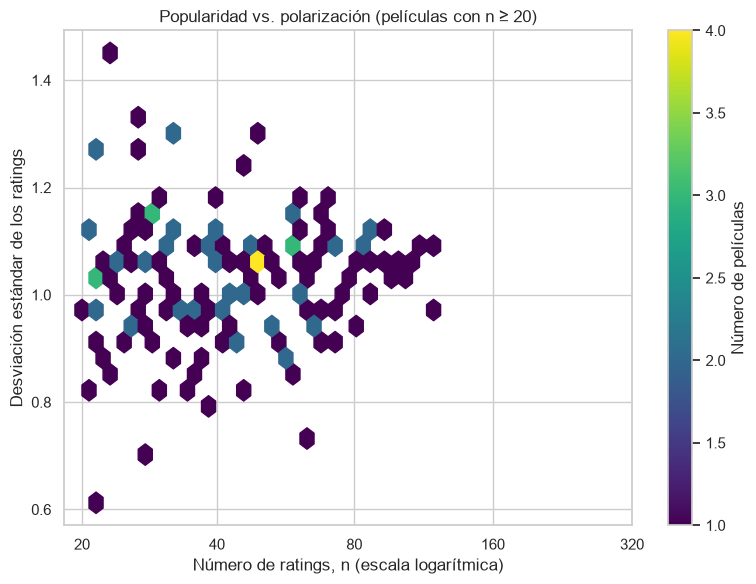

In [7]:
# TODO: hexbin de log1p(n) contra std (ax.hexbin o sns.histplot con x e y)
# rutas.guardar_figura(fig, "02_hexbin_n_std")

# hexbin de log1p(n) contra std
fig, ax = plt.subplots(figsize=(8, 6))
hb = ax.hexbin(np.log1p(stats['n']), stats['std'], gridsize=25, mincnt=1, cmap='viridis')
fig.colorbar(hb, ax=ax, label='Número de películas')

# el eje x está en log1p(n); en las marcas mostramos los valores reales de n
marcas = [20, 40, 80, 160, 320]
ax.set_xticks(np.log1p(marcas))
ax.set_xticklabels(marcas)
ax.set(
    title='Popularidad vs. polarización (películas con n ≥ 20)',
    xlabel='Número de ratings, n (escala logarítmica)',
    ylabel='Desviación estándar de los ratings',
)

plt.tight_layout()
rutas.guardar_figura(fig, '02_hexbin_n_std')
plt.show()

> **Interpretación**
> - *Qué muestra:* … Mmmmm
> - *Por qué es relevante:* …
> - *Limitaciones:* …

Rango de n, std mediana y media mediana por cuartil:
                      n_min  n_max  std_mediana  media_mediana
cuartil_popularidad                                           
Q1 (menos populares)     20     28         1.04           3.52
Q2                       29     41         1.03           3.47
Q3                       42     62         1.03           3.46
Q4 (más populares)       63    119         1.05           3.51


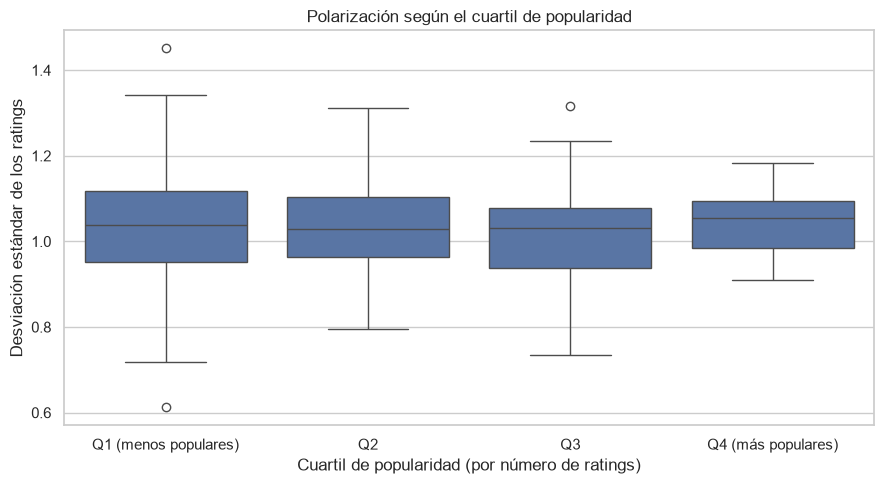

In [8]:
# TODO: boxplot de std por cuartil de popularidad (pd.qcut)
# rutas.guardar_figura(fig, "02_boxplot_std_popularidad")
stats['cuartil_popularidad'] = pd.qcut(
    stats['n'], 4,
    labels=['Q1 (menos populares)', 'Q2', 'Q3', 'Q4 (más populares)'],
)

resumen_cuartiles = stats.groupby('cuartil_popularidad', observed=True).agg(
    n_min=('n', 'min'),
    n_max=('n', 'max'),
    std_mediana=('std', 'median'),
    media_mediana=('media', 'median'),
).round(2)
rutas.guardar_tabla(resumen_cuartiles, '02_resumen_cuartiles', index=True)

print('='*50)
print('Rango de n, std mediana y media mediana por cuartil:')
print('='*50)
print(resumen_cuartiles)

fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=stats, x='cuartil_popularidad', y='std', ax=ax)
ax.set(
    title='Polarización según el cuartil de popularidad',
    xlabel='Cuartil de popularidad (por número de ratings)',
    ylabel='Desviación estándar de los ratings',
)

plt.tight_layout()
rutas.guardar_figura(fig, '02_boxplot_std_popularidad')
plt.show()

> **Interpretación**
> - *Qué muestra:* …
> - *Por qué es relevante:* …
> - *Limitaciones:* …

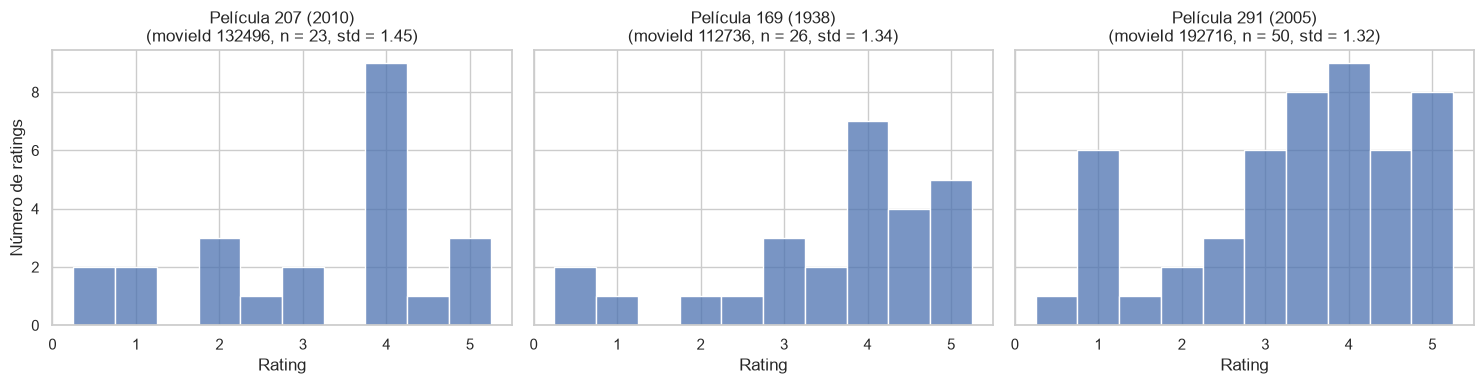

In [9]:
# TODO: histogramas de ratings de las 3 películas con mayor std
# rutas.guardar_figura(fig, "02_histogramas_polemicas")
# histogramas de ratings de las 3 películas con mayor std
top3 = stats.nlargest(3, 'std')
bins = np.arange(0.25, 5.76, 0.5)  # una barra por cada valor posible de rating

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (_, peli) in zip(axes, top3.iterrows()):
    ratings_peli = ratings.loc[ratings['movieId'] == peli['movieId'], 'rating']
    sns.histplot(x=ratings_peli, bins=bins, ax=ax)
    ax.set(
        title=f"{peli['title']}\n(movieId {peli['movieId']}, n = {peli['n']}, std = {peli['std']:.2f})",
        xlabel='Rating',
        ylabel='Número de ratings',
        xlim=(0, 5.5),
    )

plt.tight_layout()
rutas.guardar_figura(fig, '02_histogramas_polemicas')
plt.show()

> **Interpretación**
> - *Qué muestra:* …
> - *Por qué es relevante:* …
> - *Limitaciones:* …

## 5. Sensibilidad al umbral

In [10]:
# TODO: ρ(n, std) con min_n = 10, 20 y 50
# ρ(n, std) con min_n = 10, 20 y 50
filas = []  # una fila por umbral, para guardar la tabla
for umbral in [10, 20, 50]:
    stats_u = polarizacion.stats_peliculas(ratings, movies, min_n=umbral)
    filas.append({
        'umbral': f'n ≥ {umbral}',
        'películas': len(stats_u),
        'ρ Spearman (n, std)': round(stats_u['n'].corr(stats_u['std'], method='spearman'), 3),
        'r Pearson (n, std)': round(stats_u['n'].corr(stats_u['std'], method='pearson'), 3),
    })

sensibilidad = pd.DataFrame(filas)
rutas.guardar_tabla(sensibilidad, '02_sensibilidad_umbral')

print('='*50)
print('Correlación entre n y std según el umbral:')
print('='*50)
sensibilidad

Correlación entre n y std según el umbral:


,umbral,películas,"ρ Spearman (n, std)","r Pearson (n, std)"
0,n ≥ 10,216,-0.018,-0.024
1,n ≥ 20,152,0.048,0.035
2,n ≥ 50,57,0.136,0.108


## 6. Conclusión de la pregunta 1

Qué permiten concluir los datos y qué no.

…